# PRÁCTICA 2 - REGRESIÓN LINEAL MÚLTIPLE

# PASO 01 - Preparar el entorno de trabajo

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

| Librería / función | ¿Para qué se utilizará? |
|---|---|
| `pandas` | Para cargar, organizar y manipular los datos. |
| `matplotlib.pyplot` | Para crear gráficos y visualizar los resultados. |
| `train_test_split` | Para dividir los datos en entrenamiento y prueba. |
| `LinearRegression` | Para crear el modelo de regresión lineal múltiple. |
| `r2_score` | Para medir qué tanto explica el modelo la variación de los costos. |
| `mean_absolute_error` | Para calcular el error promedio de las predicciones en dólares. |

# PASO 02 - Cargar y conocer los datos

In [2]:
df = pd.read_csv("insurance.csv")

In [3]:
df.shape

(1338, 7)

In [4]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


# Interpretación

¿Cuántos asegurados y columnas tiene el dataset?

El dataset contiene 1338 asegurados y 7 columnas.

¿Qué representa una fila?

Cada fila representa a una persona asegurada y contiene sus características personales junto con el costo médico anual asociado.

¿Qué columnas contienen texto?

sex, smoker y region.

¿Qué columnas contienen números?

age, bmi, children y charges.

¿Cuál queremos predecir?

La variable objetivo es charges, que representa el costo médico anual.

# PASO 03 — Preparar los datos

In [6]:
y = df["charges"]

X = df.drop("charges", axis=1)

In [7]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

In [8]:
list(X.columns)

['age',
 'bmi',
 'children',
 'sex_male',
 'smoker_yes',
 'region_northwest',
 'region_southeast',
 'region_southwest']

In [9]:
X.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,0,1,0,0,1
1,18,33.770,1,1,0,0,1,0
2,28,33.000,3,1,0,0,1,0
3,33,22.705,0,1,0,1,0,0
4,32,28.880,0,1,0,1,0,0


Respuestas

¿En cuántas columnas se convirtieron las 6 variables originales?

En 8 columnas.

¿Qué categorías quedaron como referencia?

Con el orden habitual de get_dummies, serán:
- sex: female
- smoker: no
- region: northeast
¿Qué hace drop_first=True?

Elimina una categoría de cada variable categórica y la utiliza como referencia. No se pierde información porque la categoría eliminada puede deducirse cuando todas las demás columnas correspondientes tienen valor 0.

# PASO 04 — Dividir entrenamiento y prueba

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [11]:
print("Filas de entrenamiento:", len(X_train))
print("Filas de prueba:", len(X_test))

Filas de entrenamiento: 1070
Filas de prueba: 268


Respuestas

¿Por qué no evaluamos con los mismos datos de entrenamiento?

Porque necesitamos comprobar si el modelo funciona correctamente con datos que nunca ha visto. Evaluarlo con los mismos datos utilizados para entrenarlo podría dar una impresión demasiado optimista de su rendimiento.

¿Para qué sirve random_state=42?

Permite que la división aleatoria sea reproducible. Cada vez que ejecutemos el código obtendremos los mismos conjuntos de entrenamiento y prueba.

¿Qué pasaría si no lo fijamos?

La división podría cambiar cada vez y, como consecuencia, también podrían variar las métricas obtenidas.

# PASO 05 — Entrenar el modelo

In [12]:
modelo = LinearRegression()

In [13]:
modelo.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 256.98, 337.09, 425.28,...,-370.68,-657.86,-809.8 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['age','bmi','children',...,'region_northwest','region_southeast', 'region_southwest']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.193e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


Respuestas
¿Qué hace fit()?

fit() utiliza los datos de entrenamiento para calcular el intercepto y los coeficientes que permiten realizar las predicciones.

¿Cómo encuentra los mejores coeficientes?

La regresión lineal busca los coeficientes que minimizan las diferencias entre los valores reales y los valores predichos, utilizando el criterio de mínimos cuadrados.
Ecuación general:

charges = β0
        + β1(age)
        + β2(bmi)
        + β3(children)
        + β4(sex_male)
        + β5(smoker_yes)
        + β6(region_northwest)
        + β7(region_southeast)
        + β8(region_southwest)

β0 representa el intercepto y los demás β representan los coeficientes calculados por el modelo.

# PASO 06 — Evaluar el modelo

In [14]:
y_pred = modelo.predict(X_test)

In [15]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("R²:", r2)
print("MAE:", mae)

R²: 0.7835929767120723
MAE: 4181.194473753654


In [16]:
mediana = df["charges"].median()

print("Mediana de charges:", mediana)

Mediana de charges: 9382.033


Interpretación

El modelo obtuvo un R² de 0.7836, lo que significa que logra explicar aproximadamente el 78.36 % de la variación de los costos médicos anuales. Esto indica que las variables utilizadas permiten explicar una parte importante del costo del seguro.

El MAE fue de 4,181.19 dólares, lo que significa que, en promedio, las predicciones del modelo se alejan del costo real en aproximadamente 4,181 dólares.
La mediana de los costos es de 9,382.03 dólares. Al comparar ambos valores, el error promedio representa aproximadamente un 44.6 % de la mediana, por lo que el error todavía es considerable para una compañía de seguros.

En general, el modelo puede considerarse aceptable como una primera aproximación, ya que explica cerca del 78 % de la variación de los costos. Sin embargo, todavía presenta un margen de error importante, por lo que sería necesario mejorarlo si se quisiera utilizar para realizar estimaciones más precisas.

# PASO 07 — Interpretar los coeficientes

In [17]:
print("Intercepto:", modelo.intercept_)

Intercepto: -11931.219050326692


In [18]:
coeficientes = pd.Series(
    modelo.coef_,
    index=X.columns
)

coeficientes = coeficientes.sort_values()

coeficientes

region_southwest     -809.799354
region_southeast     -657.864297
region_northwest     -370.677326
sex_male              -18.591692
age                   256.975706
bmi                   337.092552
children              425.278784
smoker_yes          23651.128856
dtype: float64

Interpretación

La variable que más aumenta el costo del seguro es smoker_yes, con un coeficiente de 23,651.13 dólares. Esto significa que una persona fumadora tendría, en promedio, un costo anual aproximadamente 23,651 dólares mayor que una persona no fumadora, manteniendo las demás características constantes. En este caso, smoker_no es la categoría de referencia.

En cuanto a una variable numérica, age tiene un coeficiente de 256.98, lo que indica que por cada año adicional de edad, el costo anual estimado aumenta aproximadamente 257 dólares, manteniendo las demás variables constantes.

El intercepto es de −11,931.22 dólares. Este valor no tiene una interpretación práctica directa, porque representaría el costo estimado cuando todas las variables numéricas valen cero y las categóricas están en sus categorías de referencia, una situación que no representa de forma realista a un asegurado.

Finalmente, un coeficiente pequeño no significa necesariamente que una variable tenga poca influencia. Por ejemplo, aunque el coeficiente de age es mucho menor que el de smoker_yes, la edad puede variar muchos años y su efecto se va acumulando. Por eso, para evaluar la influencia de una variable también debemos considerar el rango de valores que puede tomar, y no solamente el tamaño de su coeficiente.

# PASO 08 — Gráfico real vs. predicho

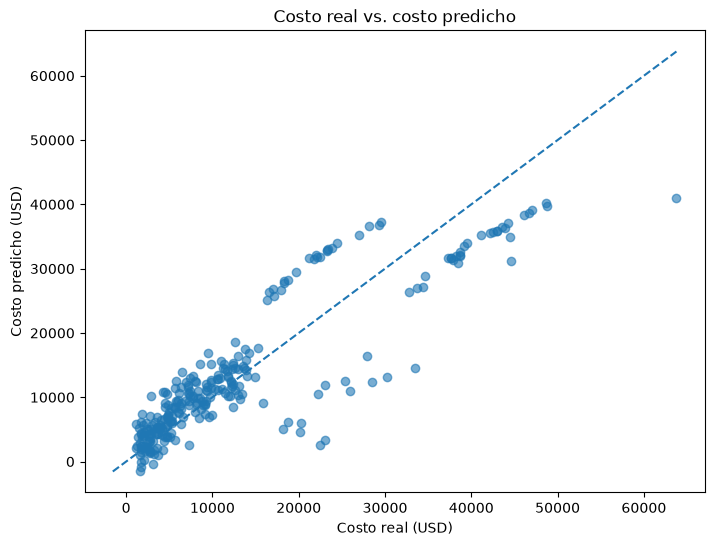

In [19]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

minimo = min(y_test.min(), y_pred.min())
maximo = max(y_test.max(), y_pred.max())

plt.plot(
    [minimo, maximo],
    [minimo, maximo],
    "--"
)

plt.xlabel("Costo real (USD)")
plt.ylabel("Costo predicho (USD)")
plt.title("Costo real vs. costo predicho")

plt.show()

Interpretación
El gráfico muestra que el modelo predice mejor los costos bajos, principalmente los valores menores a aproximadamente 15.000 USD, ya que en esta zona muchos puntos se encuentran relativamente cerca de la línea diagonal.

En los costos medios y altos se observan errores mayores. Existen varios puntos bastante alejados de la diagonal, lo que indica que las predicciones del modelo pierden precisión para algunos asegurados con costos médicos elevados.

Los puntos que están por encima de la diagonal indican que el modelo está sobreestimando el costo, es decir, predice un valor mayor al costo real. En cambio, los puntos por debajo de la diagonal representan una subestimación, porque el costo predicho es menor al real.

También se pueden observar grupos de puntos separados, especialmente en los costos medios y altos. Una posible explicación es que ciertas características generan diferencias importantes entre los asegurados. Por los resultados del Paso 07, una hipótesis razonable es que la condición de fumador influye fuertemente en estos grupos y en algunos de los errores más grandes, ya que smoker_yes fue la variable con el coeficiente más alto.

En general, el gráfico confirma que el modelo sigue la tendencia de los costos reales, pero presenta mayores dificultades para predecir algunos casos de costos elevados.

# PASO 09 — Nuevos solicitantes

In [20]:
nuevos = pd.DataFrame({
    "age": [45, 45, 25],
    "sex": ["male", "male", "female"],
    "bmi": [33.5, 33.5, 22.0],
    "children": [2, 2, 0],
    "smoker": ["yes", "no", "no"],
    "region": ["southeast", "southeast", "northwest"]
})

nuevos

,age,sex,bmi,children,smoker,region
0,45,male,33.5,2,yes,southeast
1,45,male,33.5,2,no,southeast
2,25,female,22.0,0,no,northwest


In [21]:
nuevos_codificados = pd.get_dummies(
    nuevos,
    drop_first=True,
    dtype=int
)

In [22]:
nuevos_codificados = nuevos_codificados.reindex(
    columns=X.columns,
    fill_value=0
)

In [23]:
predicciones = modelo.predict(nuevos_codificados)

print("Solicitante A:", predicciones[0])
print("Solicitante B:", predicciones[1])
print("Solicitante C:", predicciones[2])

Solicitante A: 34750.51863696532
Solicitante B: 11099.389781204105
Solicitante C: 1909.2097383263153


In [25]:
diferencia = predicciones[0] - predicciones[1]

print("Diferencia entre A y B:", diferencia)

Diferencia entre A y B: 23651.128855761213


Respuestas

Las predicciones obtenidas fueron:
- Solicitante A: 34,750.52 USD
- Solicitante B: 11,099.39 USD
- Solicitante C: 1,909.21 USD
- 
¿Por qué es necesario usar reindex?

Es necesario porque los datos de los nuevos solicitantes deben tener las mismas columnas y en el mismo orden que los datos utilizados para entrenar el modelo. reindex permite ajustar las columnas y completar con 0 aquellas que no aparecieron al realizar la codificación.

¿Qué ocurriría sin reindex?

Las columnas generadas para los nuevos solicitantes podrían ser diferentes a las utilizadas durante el entrenamiento, por lo que el modelo podría generar un error o no recibir los datos con la estructura correcta.

¿Cuánto cambia la predicción entre A y B y qué coeficiente explica la diferencia?

La diferencia es de aproximadamente 23,651.13 USD. Esto significa que al solicitante A, que es fumador, se le predice un costo anual 23,651.13 USD mayor que al solicitante B, que no fuma.

Esta diferencia coincide con el coeficiente smoker_yes = 23,651.13 obtenido en el Paso 07. Como A y B tienen las mismas características excepto que A fuma y B no, este coeficiente explica directamente la diferencia entre sus predicciones.